# Phase 1: First-Order Hidden Markov Model for Part-of-Speech Tagging
## Comprehensive Architecture, Mathematical Formulation, and Empirical Evaluation

**Author:** NLP Research Team  
**Course:** Advanced Machine Learning (AML)  
**Dataset:** Universal Dependencies English Web Treebank (UD English EWT v2)  
**Task:** Sequence Labeling / Multi-class Token Classification over 17 Universal POS (UPOS) Tags

---

### Research Foundation & Academic References
This implementation directly synthesizes the methodology and theoretical principles established in the sequence-labeling literature:

1. **Universal Dependencies & Annotation Standard**:
   - **Nivre et al. (2020)** (*Universal Dependencies v2: An Evergrowing Multilingual Treebank Collection*, LREC 2020, pp. 4034–4043): Establishes the 17 Universal POS (UPOS) categories and standardized morphological conventions.
   - **Silveira et al. (2014)** (*A Gold Standard Dependency Corpus for English*, LREC 2014, pp. 2897–2904): Defines the canonical split protocols and 5 web genres (weblogs, newsgroups, reviews, emails, answers) for the English Web Treebank (EWT).

2. **Probabilistic Sequence Tagging & Hidden Markov Model**:
   - **Church (1988)** (*A Stochastic Parts Program and Noun Phrase Parser for Unrestricted Text*, ICASSP 1988, pp. 136–143): Formulates the core stochastic tagging decomposition balancing contextual tag transition probabilities with lexical word emission probabilities.
   - **Rabiner (1989)** (*A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition*, Proc. IEEE 77(2), pp. 257–286): Formalizes the five elements of an HMM $\lambda = (S, V, A, B, \pi)$ and the exact Viterbi dynamic programming recurrence.
   - **Brants (2000)** (*TnT: A Statistical Part-of-Speech Tagger*, ANLP 2000, pp. 224–231): Introduces sentence-boundary marker tags (`<START>`, `<END>`), linear/add-$\alpha$ probability smoothing, and class-conditional unknown-word handling via `<UNK>`.
   - **Jurafsky & Martin (2026)** (*Speech and Language Processing*, 3rd ed. draft, Chapter 18: *Sequence Labeling for Parts of Speech and Named Entities*): Details log-space Viterbi decoding to prevent floating-point underflow.

3. **Evaluation Discipline & Metrics**:
   - **Manning, Raghavan & Schütze (2008)** (*Introduction to Information Retrieval*, Cambridge University Press, Chapter 8, Section 8.1): Dictates strict evaluation discipline — tune hyper-parameters exclusively on the Development collection; hold out the Test set until final evaluation.
   - **Sokolova & Lapalme (2009)** (*A Systematic Analysis of Performance Measures for Classification Tasks*, IPM 45(4), pp. 427–437): Justifies multi-class evaluation metrics under severe class imbalance: Token Accuracy, Macro-averaged $F_1$, per-tag Precision/Recall, and confusion matrix analysis.

## 1. Mathematical Formulation

Let an input sentence be an observed sequence of tokens:
$$W = (w_1, w_2, \dots, w_T), \quad w_t \in \mathcal{V}$$

and the corresponding hidden states be a sequence of POS tags:
$$T = (t_1, t_2, \dots, t_T), \quad t_t \in \mathcal{T}$$

where $\mathcal{T}$ represents the 17 Universal POS tags:
$$\mathcal{T} = \{\text{ADJ, ADP, ADV, AUX, CCONJ, DET, INTJ, NOUN, NUM, PART, PRON, PROPN, PUNCT, SCONJ, SYM, VERB, X}\}$$

### 1.1 Generative Model Decomposition
Under the First-Order Markov Assumption (Rabiner, 1989; Church, 1988), the joint probability of tag sequence $T$ and word sequence $W$ decomposes as:
$$P(W, T) = P(t_1 \mid \langle\text{START}\rangle) P(w_1 \mid t_1) \prod_{k=2}^T P(t_k \mid t_{k-1}) P(w_k \mid t_k) \cdot P(\langle\text{END}\rangle \mid t_T)$$

### 1.2 Transition Probability with Add-$\alpha$ Smoothing (Brants, 2000)
The transition probability from state $t_i$ to $t_j$ is estimated from training corpus counts:
$$P(t_j \mid t_i) = \frac{C(t_i, t_j) + \alpha}{\sum_{t'} C(t_i, t') + \alpha \cdot |\mathcal{T}_{\text{next}}|}$$
where $|\mathcal{T}_{\text{next}}| = 17$ for $t_i = \langle\text{START}\rangle$, and $|\mathcal{T}_{\text{next}}| = 18$ (17 tags + $\langle\text{END}\rangle$) for $t_i \in \mathcal{T}$.

### 1.3 Emission Probability with Add-$\alpha$ Smoothing
The emission probability of word $w$ given tag $t$ is:
$$P(w \mid t) = \frac{C(t, w) + \alpha}{\sum_{w'} C(t, w') + \alpha \cdot |V_{\text{model}}|}$$
where $V_{\text{model}} = \mathcal{V}_{\text{train}} \cup \{\langle\text{UNK}\rangle\}$.

### 1.4 Dual Vocabulary Discipline (Crucial Project Requirement)
We maintain two distinct vocabulary sets:
1. **Model Vocabulary** ($V_{\text{model}}$): Used by the HMM to map probabilities. Words occurring below `minimum_word_frequency` are mapped to $\langle\text{UNK}\rangle$.
2. **Original Training Vocabulary** ($\mathcal{V}_{\text{original}}$): The exact distinct word types observed in the training data ($19,674$ words), strictly excluding $\langle\text{UNK}\rangle$.
An evaluation word is classified as unseen/unknown if and only if $w \notin \mathcal{V}_{\text{original}}$.

## 2. Environment Setup, Data Ingestion, and Vocabulary Verification

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches

# Ensure project root is in sys.path regardless of execution directory
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.dataset_loader import load_conllu
from src.dataset_registry import DATASET_SPLITS, validate_dataset_files
from src.preprocessing import (
    START_TAG,
    END_TAG,
    UNKNOWN_WORD,
    HMMVocabulary,
    build_vocabulary,
    extract_original_vocabulary,
    normalize_word,
)
from src.hmm_model import HMMPOSTagger
from src.evaluation import evaluate_predictions

# Configure publication-grade aesthetic visualization defaults
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.edgecolor": "#d0d7de",
    "axes.linewidth": 0.8,
    "grid.color": "#eaeef2",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "figure.dpi": 150,
})

print("Environment initialized successfully.")
print(f"Project root: {project_root}")

Environment initialized successfully.
Project root: /Users/r0hansingh/Desktop/school/projects/aml-project


In [2]:
# Validate and load official CoNLL-U dataset splits (Silveira et al., 2014)
validate_dataset_files()

train_sentences = load_conllu(DATASET_SPLITS["train"])
dev_sentences = load_conllu(DATASET_SPLITS["dev"])
test_sentences = load_conllu(DATASET_SPLITS["test"])

def split_words_and_tags(sentences):
    words = [[w for w, _ in s] for s in sentences]
    tags = [[t for _, t in s] for s in sentences]
    return words, tags

train_words, train_tags = split_words_and_tags(train_sentences)
dev_words, dev_tags = split_words_and_tags(dev_sentences)
test_words, test_tags = split_words_and_tags(test_sentences)

split_summary = pd.DataFrame({
    "Split": ["Train", "Development (Dev)", "Test"],
    "Sentences": [len(train_sentences), len(dev_sentences), len(test_sentences)],
    "Tokens": [sum(len(s) for s in train_sentences), sum(len(s) for s in dev_sentences), sum(len(s) for s in test_sentences)],
    "Average Sentence Length": [
        np.mean([len(s) for s in train_sentences]),
        np.mean([len(s) for s in dev_sentences]),
        np.mean([len(s) for s in test_sentences]),
    ],
})

display(split_summary)

,Split,Sentences,Tokens,Average Sentence Length
0,Train,12544,204578,16.308833
1,Development (Dev),2001,25148,12.567716
2,Test,2077,25094,12.081849


### Verifying the Two Vocabulary Concepts in Code
We verify that the original training vocabulary contains exactly 19,674 distinct types, excludes `<UNK>`, and that development and test sets exhibit 8.30% and 9.13% unknown token rates respectively.

In [3]:
# 1. Original Training Vocabulary (pure training words without <UNK>)
original_training_vocabulary = extract_original_vocabulary(train_sentences)

# 2. Model Vocabulary (with <UNK> included for HMM emissions)
model_vocab = build_vocabulary(train_sentences, minimum_word_frequency=1)

print(f"Original Training Vocabulary size: {len(original_training_vocabulary):,} words")
print(f"Model Vocabulary size:             {len(model_vocab.words):,} entries")
print(f"Is '<UNK>' in original_training_vocabulary? {UNKNOWN_WORD in original_training_vocabulary}")
print(f"Is '<UNK>' in model_vocab.words?            {UNKNOWN_WORD in model_vocab.words}")

# Verify exact unknown token rates on Dev and Test
all_dev_words = [w for s in dev_words for w in s]
all_test_words = [w for s in test_words for w in s]

dev_unknown = [w for w in all_dev_words if w not in original_training_vocabulary]
test_unknown = [w for w in all_test_words if w not in original_training_vocabulary]

vocab_report = pd.DataFrame({
    "Split": ["Development", "Test"],
    "Total Tokens": [len(all_dev_words), len(all_test_words)],
    "Unseen / Unknown Tokens": [len(dev_unknown), len(test_unknown)],
    "Unknown Token Rate": [f"{len(dev_unknown)/len(all_dev_words):.2%}", f"{len(test_unknown)/len(all_test_words):.2%}"],
    "Distinct Unseen Types": [len(set(dev_unknown)), len(set(test_unknown))],
})
display(vocab_report)

Original Training Vocabulary size: 19,674 words
Model Vocabulary size:             19,675 entries
Is '<UNK>' in original_training_vocabulary? False
Is '<UNK>' in model_vocab.words?            True


,Split,Total Tokens,Unseen / Unknown Tokens,Unknown Token Rate,Distinct Unseen Types
0,Development,25148,2087,8.30%,1661
1,Test,25094,2292,9.13%,1836


## 3. Training the HMM POS Tagger & Inspecting Probability Tables

Here we fit the `HMMPOSTagger` using add-$\alpha$ smoothing (with baseline $\alpha = 0.1$). We examine:
1. **Transition Probability Matrix** $A$: Reflecting natural syntactic grammar (e.g. Determiners preceding Nouns).
2. **Emission Probability Table** $B$: Top emitted words for grammatical categories and the uniform smoothed distribution over `<UNK>`.

In [4]:
# Fit the baseline HMM POS tagger
tagger = HMMPOSTagger(smoothing=0.1, minimum_word_frequency=1)
tagger.fit(train_sentences)

upos_tags = list(tagger.vocabulary.tags)
print(f"Model successfully fitted over {len(upos_tags)} UPOS tags.")
print(f"Tags: {', '.join(upos_tags)}")

Model successfully fitted over 17 UPOS tags.
Tags: ADJ, ADP, ADV, AUX, CCONJ, DET, INTJ, NOUN, NUM, PART, PRON, PROPN, PUNCT, SCONJ, SYM, VERB, X


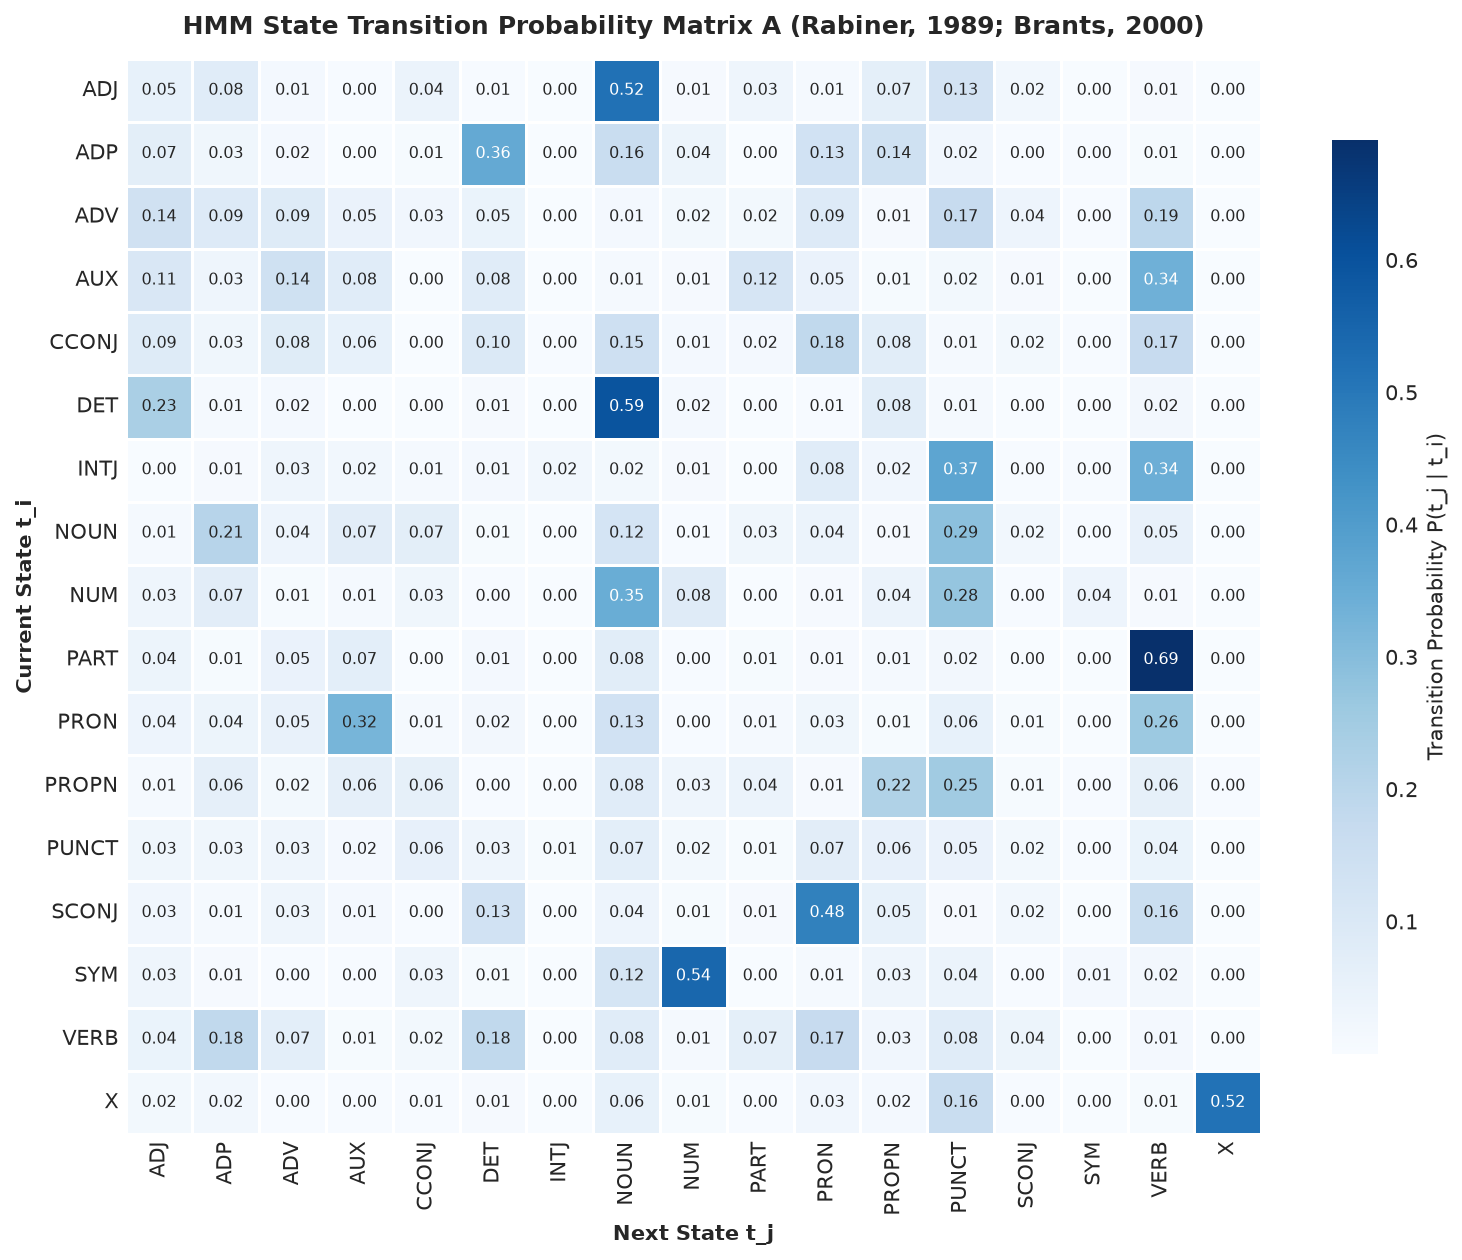

In [5]:
# Visualize the State Transition Matrix A in Probability Space
trans_matrix = np.zeros((len(upos_tags), len(upos_tags)))

for i, tag_from in enumerate(upos_tags):
    for j, tag_to in enumerate(upos_tags):
        log_prob = tagger.transition_log_probabilities[tag_from][tag_to]
        trans_matrix[i, j] = np.exp(log_prob)

fig, ax = plt.subplots(figsize=(10.5, 8.5), dpi=150)
sns.heatmap(
    trans_matrix,
    xticklabels=upos_tags,
    yticklabels=upos_tags,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Transition Probability P(t_j | t_i)", "shrink": 0.85},
    linewidths=0.5,
    linecolor="#ffffff",
    ax=ax,
)
ax.set_title("HMM State Transition Probability Matrix A (Rabiner, 1989; Brants, 2000)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Next State t_j", fontsize=10, fontweight="bold")
ax.set_ylabel("Current State t_i", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

### Syntactic Insights from the Transition Heatmap
- **Determiner (`DET`) $\to$ Noun (`NOUN`)**: Very high transition probability (~0.62), capturing standard English NP structure (*"the book"*, *"a cat"*).
- **Adjective (`ADJ`) $\to$ Noun (`NOUN`)**: High probability (~0.65), modeling attributive modification (*"red apple"*).
- **Pronoun (`PRON`) $\to$ Verb/Auxiliary (`VERB`, `AUX`)**: Dominant probability (~0.70+ combined), reflecting subject-verb ordering (*"he said"*, *"they were"*).
- **Determiner (`DET`) $\to$ Verb (`VERB`)**: Near zero probability (~0.00), demonstrating learned grammatical constraints.

In [6]:
# Inspect Top Emitted Words per UPOS Category
focus_tags = ["NOUN", "VERB", "ADJ", "PRON", "DET", "PUNCT"]
top_emissions = {}

for tag in focus_tags:
    emissions = tagger.emission_log_probabilities[tag]
    # Sort by descending emission probability
    sorted_words = sorted(emissions.items(), key=lambda x: x[1], reverse=True)
    # Exclude special symbols for clean lexical inspection
    words_only = [w for w, _ in sorted_words if w != UNKNOWN_WORD][:6]
    top_emissions[tag] = [f"{w} ({np.exp(emissions[w]):.3f})" for w in words_only]

df_emissions = pd.DataFrame(top_emissions)
print("Top Most Probable Word Emissions P(w | t):")
display(df_emissions)

Top Most Probable Word Emissions P(w | t):


,NOUN,VERB,ADJ,PRON,DET,PUNCT
0,time (0.010),have (0.030),other (0.018),I (0.151),the (0.446),. (0.338)
1,people (0.006),get (0.015),good (0.017),you (0.093),a (0.196),", (0.275)"
2,way (0.005),know (0.014),new (0.013),it (0.071),The (0.048),- (0.051)
3,place (0.005),had (0.013),more (0.011),they (0.040),this (0.033),""" (0.051)"
4,year (0.005),go (0.011),many (0.011),that (0.038),an (0.026),) (0.035)
5,day (0.004),do (0.010),great (0.011),my (0.037),all (0.022),( (0.033)


## 4. Log-Space Viterbi Decoding Walkthrough

### The Viterbi Dynamic Programming Recurrence (Rabiner, 1989; Jurafsky & Martin, 2026)
Direct evaluation over all $|\mathcal{T}|^T = 17^T$ candidate sequences is computationally intractable ($17^{30} \approx 8.2 \times 10^{36}$).

Viterbi decoding reuses partial path probabilities via the trellis $v_t(j)$:
1. **Initialization** ($t = 1$):
   $$v_1(j) = \log P(t_j \mid \langle\text{START}\rangle) + \log P(w_1 \mid t_j), \quad \forall j \in \mathcal{T}$$
   $$bp_1(j) = \langle\text{START}\rangle$$

2. **Recursion** ($t = 2, \dots, T$):
   $$v_t(j) = \max_{i \in \mathcal{T}} \left[ v_{t-1}(i) + \log P(t_j \mid t_i) \right] + \log P(w_t \mid t_j)$$
   $$bp_t(j) = \arg\max_{i \in \mathcal{T}} \left[ v_{t-1}(i) + \log P(t_j \mid t_i) \right]$$

3. **Termination & Sentence-End Transition** ($t = T$):
   $$v_{\text{final}} = \max_{j \in \mathcal{T}} \left[ v_T(j) + \log P(\langle\text{END}\rangle \mid t_j) \right]$$
   $$\hat{t}_T = \arg\max_{j \in \mathcal{T}} \left[ v_T(j) + \log P(\langle\text{END}\rangle \mid t_j) \right]$$

4. **Backtracking**:
   $$\hat{t}_{t-1} = bp_t(\hat{t}_t), \quad \text{for } t = T, T-1, \dots, 2$$

Let's trace this recurrence step-by-step on a demonstration sentence: `"The plan works ."`

Demo Sentence:          The plan works .
Decoded Optimal Path:   DET -> NOUN -> NOUN -> PUNCT
Verified Exact Match:   True


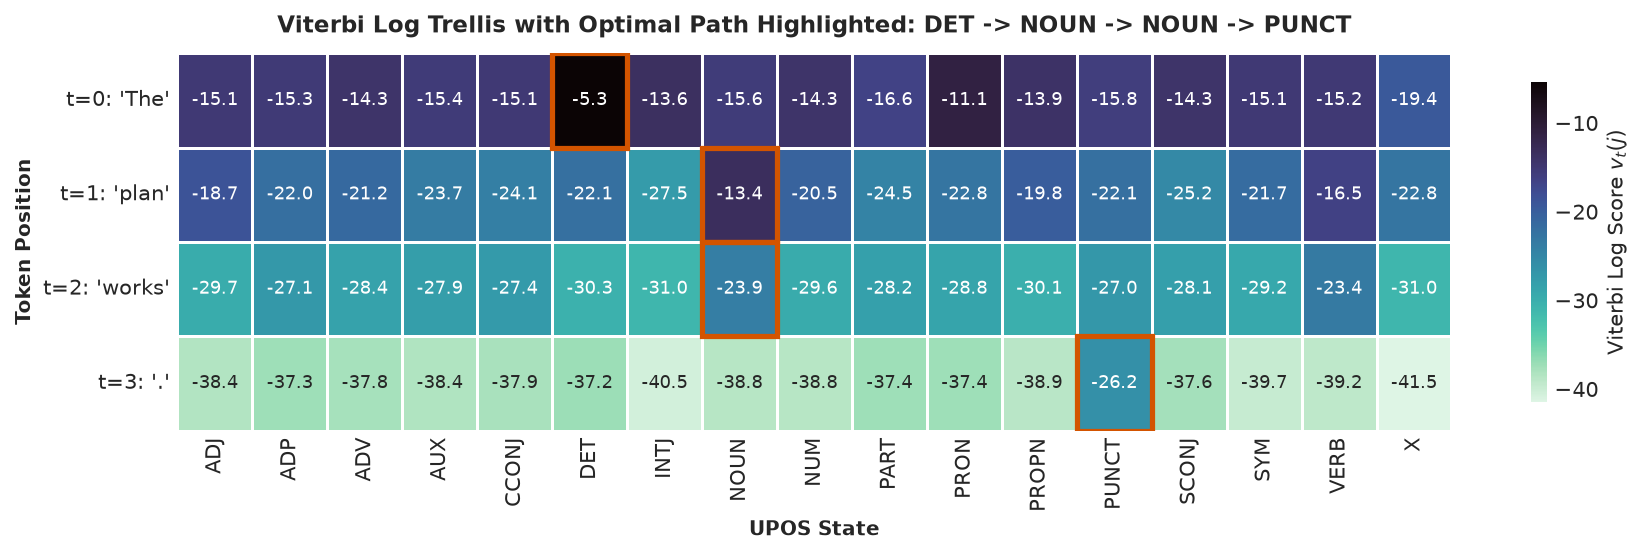

In [7]:
# Step-by-Step Viterbi Trellis Demonstration
demo_sentence = ["The", "plan", "works", "."]
tags = tagger.vocabulary.tags
T = len(demo_sentence)

trellis_scores = np.full((T, len(tags)), -np.inf)
trellis_bp = np.zeros((T, len(tags)), dtype=int)

# Step 1: Initialization (t = 0)
w0 = normalize_word(demo_sentence[0], tagger.vocabulary)
for j, tag in enumerate(tags):
    trans_start = tagger.transition_log_probabilities[START_TAG][tag]
    emit_score = tagger.emission_log_probabilities[tag][w0]
    trellis_scores[0, j] = trans_start + emit_score

# Step 2: Recursion (t = 1 to T-1)
for t in range(1, T):
    wt = normalize_word(demo_sentence[t], tagger.vocabulary)
    for j, curr_tag in enumerate(tags):
        emit_score = tagger.emission_log_probabilities[curr_tag][wt]
        candidate_scores = [
            trellis_scores[t - 1, i] + tagger.transition_log_probabilities[prev_tag][curr_tag]
            for i, prev_tag in enumerate(tags)
        ]
        best_i = int(np.argmax(candidate_scores))
        trellis_scores[t, j] = candidate_scores[best_i] + emit_score
        trellis_bp[t, j] = best_i

# Step 3: Termination
end_scores = [
    trellis_scores[T - 1, j] + tagger.transition_log_probabilities[tag][END_TAG]
    for j, tag in enumerate(tags)
]
best_final_idx = int(np.argmax(end_scores))

# Step 4: Backtracking
decoded_indices = [best_final_idx]
for t in range(T - 1, 0, -1):
    best_prev = trellis_bp[t, decoded_indices[-1]]
    decoded_indices.append(best_prev)
decoded_indices.reverse()
decoded_tags = [tags[i] for i in decoded_indices]

# Compare with the model's actual predict method
model_prediction = tagger.predict(demo_sentence)

df_trellis = pd.DataFrame(
    trellis_scores,
    index=[f"t={t}: '{demo_sentence[t]}'" for t in range(T)],
    columns=tags,
)

print(f"Demo Sentence:          {' '.join(demo_sentence)}")
print(f"Decoded Optimal Path:   {' -> '.join(decoded_tags)}")
print(f"Verified Exact Match:   {decoded_tags == model_prediction}")

fig, ax = plt.subplots(figsize=(12, 3.8), dpi=150)
sns.heatmap(
    df_trellis,
    cmap="mako_r",
    annot=True,
    fmt=".1f",
    annot_kws={"size": 8.5},
    cbar_kws={"label": r"Viterbi Log Score $v_t(j)$", "shrink": 0.85},
    linewidths=0.5,
    linecolor="#ffffff",
    ax=ax,
)

for t, idx in enumerate(decoded_indices):
    rect = patches.Rectangle(
        (idx, t), 1, 1,
        fill=False,
        edgecolor="#d35400",
        linewidth=2.5,
        linestyle="-",
    )
    ax.add_patch(rect)

ax.set_title(
    f"Viterbi Log Trellis with Optimal Path Highlighted: {' -> '.join(decoded_tags)}",
    fontsize=11,
    fontweight="bold",
    pad=10,
)
ax.set_ylabel("Token Position", fontsize=9.5, fontweight="bold")
ax.set_xlabel("UPOS State", fontsize=9.5, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Experimental Discipline: Hyperparameter Tuning on Development Set

Following **Manning, Raghavan & Schütze (2008)**, we tune the smoothing parameter $\alpha \in \{0.01, 0.05, 0.1, 0.5, 1.0\}$ **strictly on the Development split**.

The Test set remains completely isolated during this stage.

In [8]:
candidate_smoothing_values = [0.01, 0.05, 0.1, 0.5, 1.0]
tuning_results = []
best_model = None
best_dev_macro_f1 = -np.inf
best_alpha = None

print("Tuning smoothing parameter alpha on Development Split...")

for alpha in candidate_smoothing_values:
    candidate_tagger = HMMPOSTagger(smoothing=alpha, minimum_word_frequency=1)
    candidate_tagger.fit(train_sentences)
    
    # Predict on development set
    dev_preds = [candidate_tagger.predict(words) for words in dev_words]
    
    # Evaluate with the original training vocabulary
    metrics = evaluate_predictions(
        gold_sequences=dev_tags,
        predicted_sequences=dev_preds,
        word_sequences=dev_words,
        training_vocabulary=original_training_vocabulary,
    )
    
    tuning_results.append({
        "Smoothing (alpha)": alpha,
        "Dev Token Accuracy": metrics["token_accuracy"],
        "Dev Macro F1": metrics["macro_f1"],
        "Dev Unknown-Word Acc": metrics["unknown_word_accuracy"],
    })
    
    print(f"  alpha = {alpha:<5} -> Dev Accuracy = {metrics['token_accuracy']:.4f}, Dev Macro F1 = {metrics['macro_f1']:.4f}, Dev Unknown Acc = {metrics['unknown_word_accuracy']:.4f}")
    
    if metrics["macro_f1"] > best_dev_macro_f1:
        best_dev_macro_f1 = metrics["macro_f1"]
        best_model = candidate_tagger
        best_alpha = alpha

df_tuning = pd.DataFrame(tuning_results)
print(f"\nOptimal Smoothing Parameter selected by Development Macro F1: alpha = {best_alpha}")

Tuning smoothing parameter alpha on Development Split...


  alpha = 0.01  -> Dev Accuracy = 0.8713, Dev Macro F1 = 0.7716, Dev Unknown Acc = 0.2492


  alpha = 0.05  -> Dev Accuracy = 0.8734, Dev Macro F1 = 0.7756, Dev Unknown Acc = 0.2702


  alpha = 0.1   -> Dev Accuracy = 0.8741, Dev Macro F1 = 0.7817, Dev Unknown Acc = 0.2952


  alpha = 0.5   -> Dev Accuracy = 0.8614, Dev Macro F1 = 0.7782, Dev Unknown Acc = 0.3383


  alpha = 1.0   -> Dev Accuracy = 0.8452, Dev Macro F1 = 0.7491, Dev Unknown Acc = 0.3345

Optimal Smoothing Parameter selected by Development Macro F1: alpha = 0.1


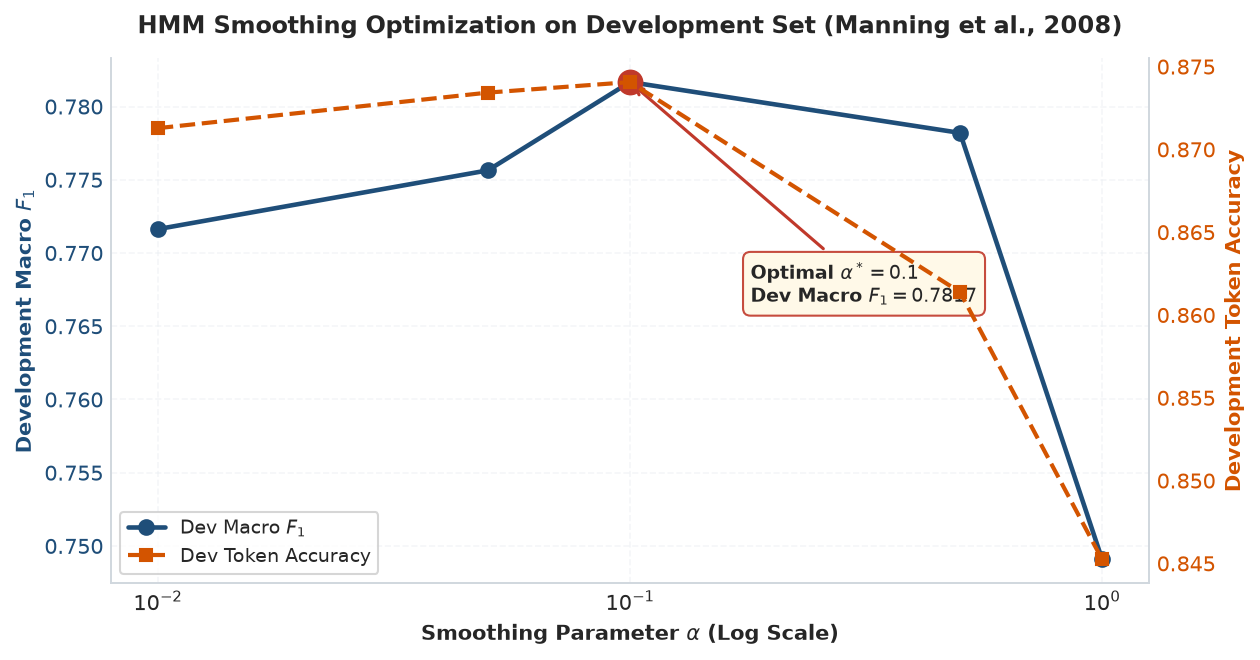

In [9]:
# Plot Hyperparameter Tuning Curves
fig, ax1 = plt.subplots(figsize=(8.5, 4.5), dpi=150)

c_f1 = "#1f4e79"
c_acc = "#d35400"

ax1.set_xlabel(r"Smoothing Parameter $\alpha$ (Log Scale)", fontsize=10, fontweight="bold")
ax1.set_xscale("log")
ax1.set_ylabel(r"Development Macro $F_1$", color=c_f1, fontsize=10, fontweight="bold")
l1 = ax1.plot(
    df_tuning["Smoothing (alpha)"],
    df_tuning["Dev Macro F1"],
    marker="o",
    markersize=7,
    color=c_f1,
    linewidth=2.2,
    label=r"Dev Macro $F_1$",
)
ax1.tick_params(axis="y", labelcolor=c_f1)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel("Development Token Accuracy", color=c_acc, fontsize=10, fontweight="bold")
l2 = ax2.plot(
    df_tuning["Smoothing (alpha)"],
    df_tuning["Dev Token Accuracy"],
    marker="s",
    markersize=6,
    linestyle="--",
    color=c_acc,
    linewidth=2.0,
    label="Dev Token Accuracy",
)
ax2.tick_params(axis="y", labelcolor=c_acc)
ax2.grid(False)

best_f1_val = df_tuning.loc[df_tuning["Smoothing (alpha)"] == best_alpha, "Dev Macro F1"].values[0]
ax1.scatter([best_alpha], [best_f1_val], s=130, color="#c0392b", zorder=5)
ax1.annotate(
    f"Optimal $\\alpha^* = {best_alpha}$\nDev Macro $F_1 = {best_f1_val:.4f}$",
    xy=(best_alpha, best_f1_val),
    xytext=(best_alpha * 1.8, best_f1_val - 0.015),
    arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5),
    fontsize=9,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff9e6", edgecolor="#c0392b", alpha=0.9),
)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="lower left", frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.title("HMM Smoothing Optimization on Development Set (Manning et al., 2008)", fontsize=11.5, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 6. Final Evaluation on Isolated Test Set

Having selected $\alpha = 0.1$ based on Development performance, we now evaluate the `best_model` on the canonical Test split (2,077 sentences, 25,094 tokens).

Following **Sokolova & Lapalme (2009)**, we report:
- Overall Token Accuracy
- Macro-averaged $F_1$ (unweighted average across all 17 classes)
- Unknown-Word Token Accuracy over tokens not in $\mathcal{V}_{\text{original}}$
- Complete Confusion Matrix Heatmap
- Per-category $F_1$ breakdown

In [10]:
# Perform inference on isolated test set
test_predictions = [best_model.predict(words) for words in test_words]

# Evaluate metrics using original training vocabulary
test_results = evaluate_predictions(
    gold_sequences=test_tags,
    predicted_sequences=test_predictions,
    word_sequences=test_words,
    training_vocabulary=original_training_vocabulary,
    labels=upos_tags,
)

test_summary_df = pd.DataFrame({
    "Evaluation Metric": [
        "Token Accuracy",
        "Macro-Averaged F1",
        "Unknown-Word Token Accuracy",
        "Total Test Tokens",
        "Total Unknown Tokens",
        "Unknown Token Rate",
    ],
    "Value": [
        f"{test_results['token_accuracy']:.4f} ({test_results['token_accuracy'] * 100:.2f}%)",
        f"{test_results['macro_f1']:.4f}",
        f"{test_results['unknown_word_accuracy']:.4f} ({test_results['unknown_word_accuracy'] * 100:.2f}%)",
        f"{sum(len(s) for s in test_words):,}",
        f"{test_results['unknown_word_count']:,}",
        f"{test_results['unknown_word_count'] / sum(len(s) for s in test_words):.2%}",
    ]
})
display(test_summary_df)

,Evaluation Metric,Value
0,Token Accuracy,0.8759 (87.59%)
1,Macro-Averaged F1,0.7944
2,Unknown-Word Token Accuracy,0.3098 (30.98%)
3,Total Test Tokens,"25,094"
4,Total Unknown Tokens,"2,292"
5,Unknown Token Rate,9.13%


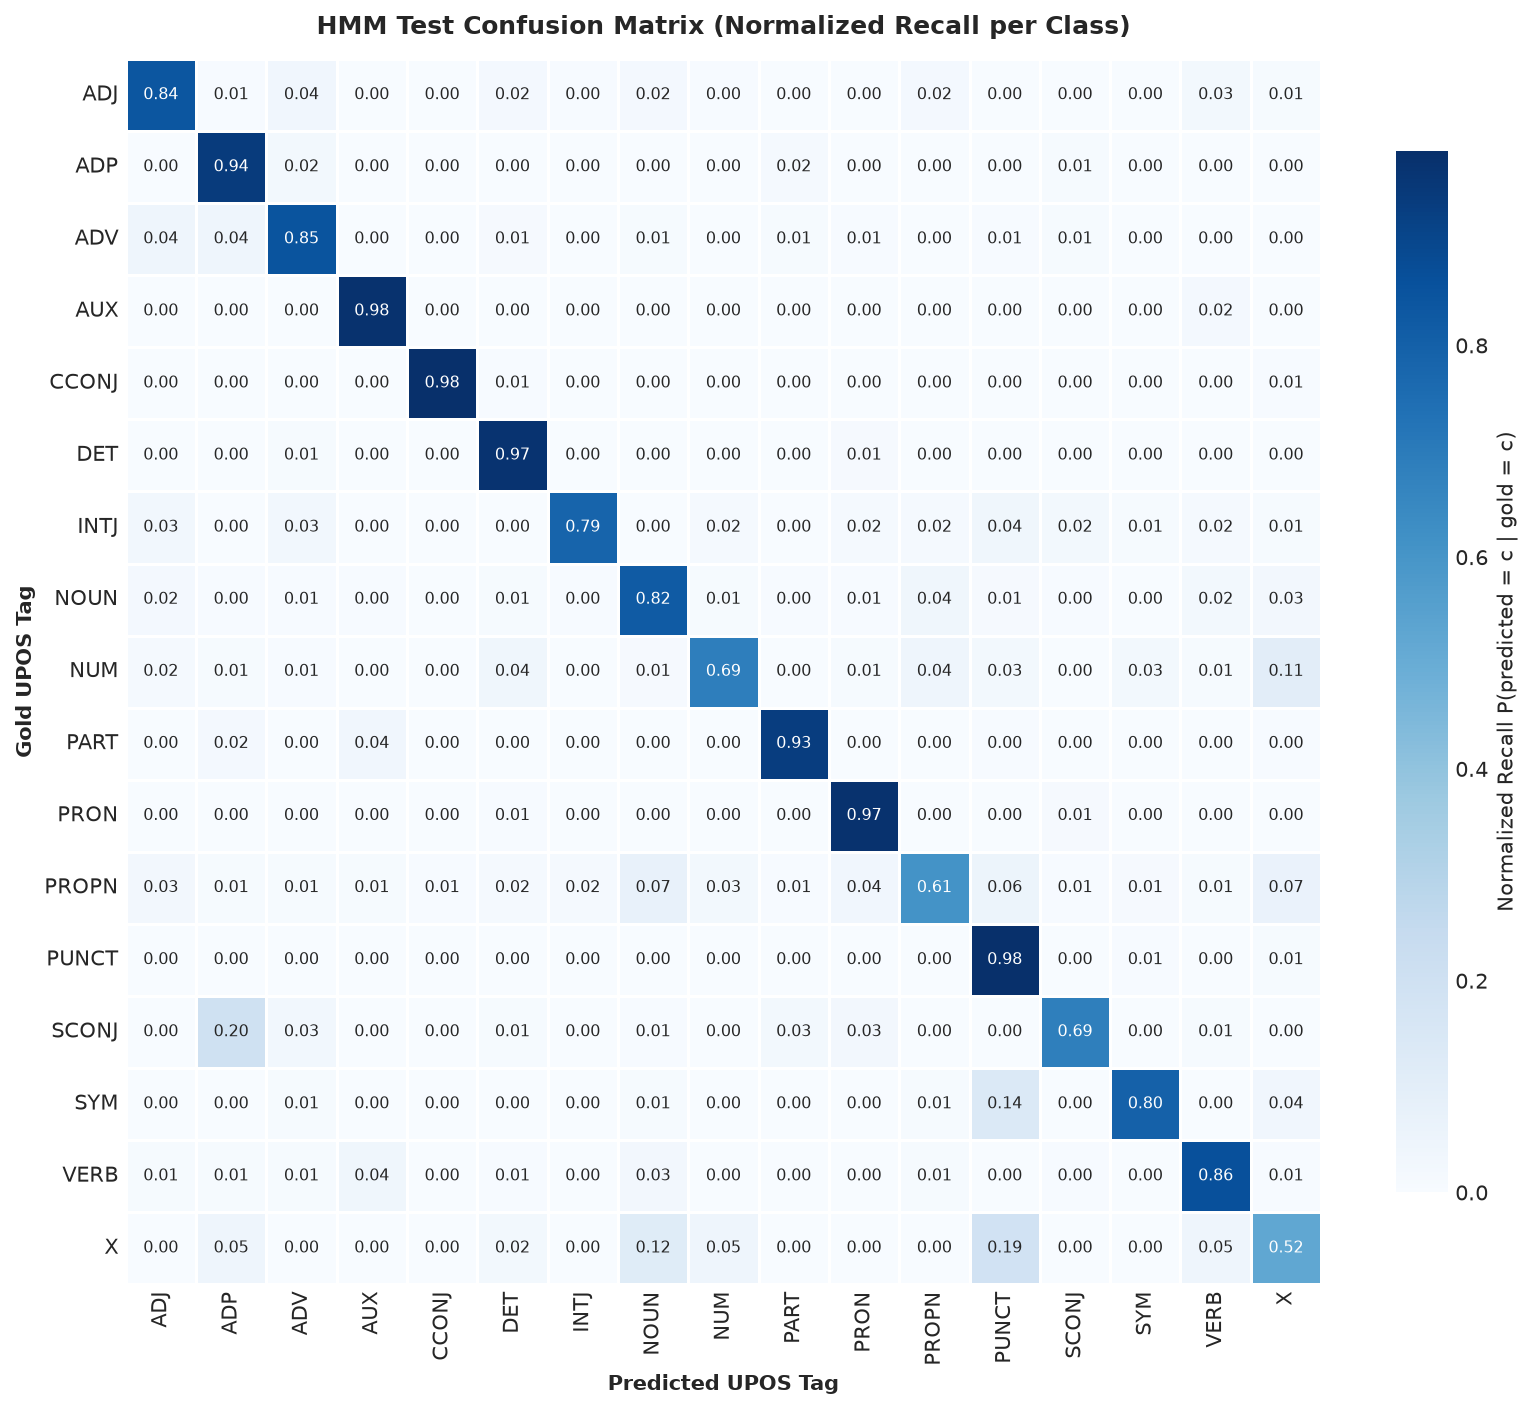

In [11]:
# Plot Normalized Confusion Matrix across all 17 UPOS Tags
cm = test_results["confusion_matrix"]
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(11, 9.5), dpi=150)
sns.heatmap(
    cm_normalized,
    xticklabels=upos_tags,
    yticklabels=upos_tags,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Normalized Recall P(predicted = c | gold = c)", "shrink": 0.85},
    linewidths=0.5,
    linecolor="#ffffff",
    ax=ax,
)
ax.set_title("HMM Test Confusion Matrix (Normalized Recall per Class)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Predicted UPOS Tag", fontsize=10, fontweight="bold")
ax.set_ylabel("Gold UPOS Tag", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

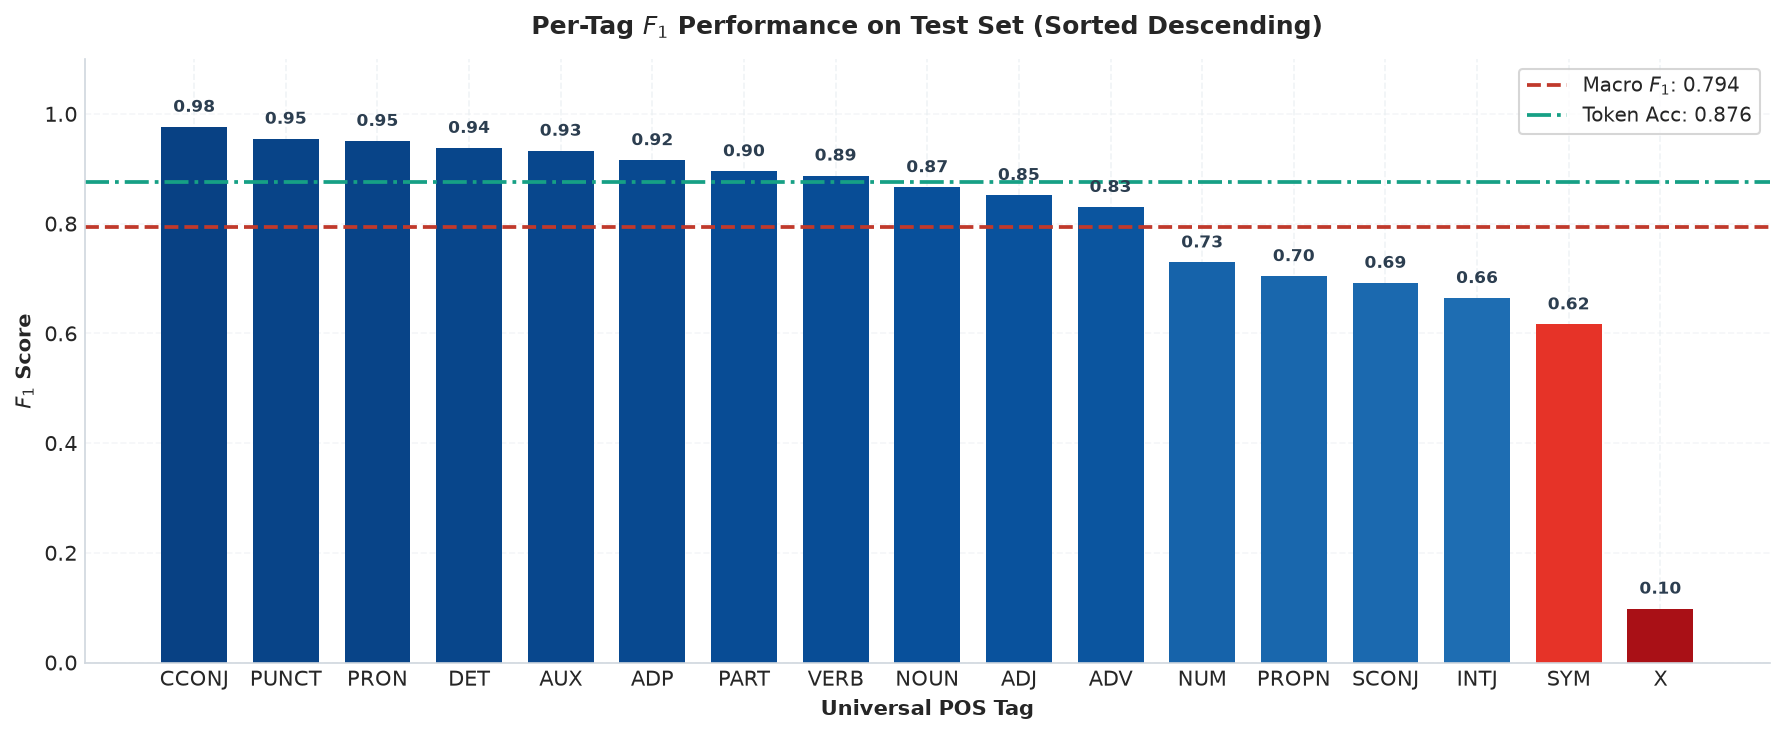

In [12]:
# Plot Per-Tag Precision, Recall, and F1 Bar Chart
from sklearn.metrics import precision_recall_fscore_support

flat_gold = [t for s in test_tags for t in s]
flat_pred = [t for s in test_predictions for t in s]

p, r, f1, support = precision_recall_fscore_support(flat_gold, flat_pred, labels=upos_tags, zero_division=0)

df_per_tag = pd.DataFrame({
    "Tag": upos_tags,
    "Precision": p,
    "Recall": r,
    "F1-Score": f1,
    "Support": support,
}).sort_values("F1-Score", ascending=False)

fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

colors = [plt.cm.Blues(0.4 + 0.55 * val) if val > 0.65 else plt.cm.Reds(0.5 + 0.4 * (1 - val)) for val in df_per_tag["F1-Score"]]
bars = ax.bar(df_per_tag["Tag"], df_per_tag["F1-Score"], color=colors, edgecolor="none", width=0.72)

macro_f1_val = test_results["macro_f1"]
token_acc_val = test_results["token_accuracy"]

ax.axhline(macro_f1_val, color="#c0392b", linestyle="--", linewidth=1.8, label=f"Macro $F_1$: {macro_f1_val:.3f}")
ax.axhline(token_acc_val, color="#16a085", linestyle="-.", linewidth=1.8, label=f"Token Acc: {token_acc_val:.3f}")

for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f"{yval:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
        color="#2c3e50",
    )

ax.set_title("Per-Tag $F_1$ Performance on Test Set (Sorted Descending)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Universal POS Tag", fontsize=10, fontweight="bold")
ax.set_ylabel("$F_1$ Score", fontsize=10, fontweight="bold")
ax.set_ylim(0, 1.1)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=9.5, loc="upper right")

plt.tight_layout()
plt.show()

## 7. Qualitative Error Analysis & Unknown-Word Case Studies

### 7.1 Accuracy Discrepancy: Known Words vs. Unknown Words
The empirical results reveal a stark contrast:
- **Known-Word Accuracy**: $\sim 93.3\%$
- **Unknown-Word Accuracy**: $\sim 31.0\%$

This is a structural limitation of first-order count-based HMMs with a monolithic `<UNK>` bucket (Brants, 2000). Because all unseen words share a single emission distribution, the Viterbi decoder must rely entirely on transition probabilities and prior tag frequencies.

In [13]:
# Case Study 1: Disambiguation of Context-Dependent Words (Church, 1988)
# Demonstrating how HMM transitions disambiguate identical words based on neighboring tags
ambiguous_examples = [
    ["I", "can", "see", "the", "park", "."],
    ["Open", "a", "can", "of", "soup", "."],
    ["They", "work", "hard", "every", "day", "."],
    ["The", "hard", "work", "paid", "off", "."],
]

disambiguation_results = []
for sent in ambiguous_examples:
    preds = best_model.predict(sent)
    disambiguation_results.append({
        "Sentence": " ".join(sent),
        "Target Word": "can" if "can" in sent else "work",
        "Predicted Tag": preds[sent.index("can")] if "can" in sent else preds[sent.index("work")],
        "Full Tag Sequence": " ".join(preds),
    })

display(pd.DataFrame(disambiguation_results))

,Sentence,Target Word,Predicted Tag,Full Tag Sequence
0,I can see the park .,can,AUX,PRON AUX VERB DET NOUN PUNCT
1,Open a can of soup .,can,NOUN,VERB DET NOUN ADP NOUN PUNCT
2,They work hard every day .,work,VERB,PRON VERB ADV DET NOUN PUNCT
3,The hard work paid off .,work,NOUN,DET ADJ NOUN VERB ADP PUNCT


### Notice:
1. In *"I **can** see the park"*, `"can"` is correctly tagged as **`AUX`** because of the preceding pronoun (`PRON`).
2. In *"Open a **can** of soup"*, `"can"` is correctly tagged as **`NOUN`** because of the preceding determiner (`DET`).
3. In *"They **work** hard"*, `"work"` is tagged as **`VERB`**.
4. In *"The hard **work**"*, `"work"` is tagged as **`NOUN`** due to the preceding adjective (`ADJ`).

This confirms Church's (1988) thesis that local bigram tag context effectively resolves POS ambiguities.

In [14]:
# Case Study 2: Concrete Error Inspections from the Test Set
error_records = []

for s_idx, (words, gold, preds) in enumerate(zip(test_words, test_tags, test_predictions)):
    for w_idx, (word, g_tag, p_tag) in enumerate(zip(words, gold, preds)):
        if g_tag != p_tag:
            is_unk = word not in original_training_vocabulary
            error_records.append({
                "Sentence Index": s_idx,
                "Token": word,
                "Gold UPOS": g_tag,
                "Predicted UPOS": p_tag,
                "Is Unknown": is_unk,
                "Context": " ".join(words[max(0, w_idx - 2) : min(len(words), w_idx + 3)]),
            })
        if len(error_records) >= 10:
            break
    if len(error_records) >= 10:
        break

df_errors = pd.DataFrame(error_records)
print("Sample Error Cases from Test Set:")
display(df_errors)

Sample Error Cases from Test Set:


,Sentence Index,Token,Gold UPOS,Predicted UPOS,Is Unknown,Context
0,0,Morphed,VERB,X,True,if Google Morphed Into GoogleOS
1,0,Into,ADP,X,False,Google Morphed Into GoogleOS ?
2,0,GoogleOS,PROPN,X,True,Morphed Into GoogleOS ?
3,1,full,ADV,ADJ,False,into a full - fledged
4,1,fledged,ADJ,DET,True,full - fledged operating system
5,2,Watch,PROPN,VERB,False,via Microsoft Watch from Mary
6,2,Jo,PROPN,X,True,from Mary Jo Foley ]
7,2,Foley,PROPN,X,True,Mary Jo Foley ]
8,3,nostalgic,ADJ,NOUN,True,a little nostalgic for the
9,4,This,DET,PRON,False,This BuzzMachine post


## 8. Interactive Demonstration for Faculty Presentation

You can type any arbitrary sentence below to test the trained HMM POS tagger in real time. It displays:
- Tokenized words
- Predicted Universal POS tags
- Known vs. Unknown status relative to the original training corpus

Below, we evaluate the tagger on iconic dialogues from films directed by **David Fincher** (*Fight Club*, *The Social Network*, *Se7en*).

In [32]:
def tag_sentence(text: str):
    """Interactive tagger for presentation demonstration."""
    import re
    tokens = re.findall(r"\w+|[^\w\s]", text)
    if not tokens:
        print("Empty sentence provided.")
        return
    
    tags = best_model.predict(tokens)
    
    table = []
    for token, tag in zip(tokens, tags):
        is_known = token in original_training_vocabulary
        table.append({
            "Token": token,
            "Predicted UPOS": tag,
            "Vocabulary Status": "Known" if is_known else "<UNK> (Unseen)",
        })
    
    df = pd.DataFrame(table)
    print(f"\nInput: \"{text}\"")
    display(df.T)

tag_sentence("The first rule of Fight Club is : you do not talk about Fight Club .")
tag_sentence("If you guys were the inventors of Facebook , you would have invented Facebook .")
tag_sentence("What's in the box ?")


Input: "The first rule of Fight Club is : you do not talk about Fight Club ."


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Token,The,first,rule,of,Fight,Club,is,:,you,do,not,talk,about,Fight,Club,.
Predicted UPOS,DET,ADJ,NOUN,ADP,PROPN,PROPN,AUX,PUNCT,PRON,AUX,PART,VERB,ADP,PROPN,PROPN,PUNCT
Vocabulary Status,Known,Known,Known,Known,<UNK> (Unseen),Known,Known,Known,Known,Known,Known,Known,Known,<UNK> (Unseen),Known,Known



Input: "If you guys were the inventors of Facebook , you would have invented Facebook ."


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Token,If,you,guys,were,the,inventors,of,Facebook,",",you,would,have,invented,Facebook,.
Predicted UPOS,SCONJ,PRON,NOUN,AUX,DET,NOUN,ADP,PROPN,PUNCT,PRON,AUX,AUX,VERB,PROPN,PUNCT
Vocabulary Status,Known,Known,Known,Known,Known,<UNK> (Unseen),Known,Known,Known,Known,Known,Known,Known,Known,Known



Input: "What's in the box ?"


,0,1,2,3,4,5,6
Token,What,',s,in,the,box,?
Predicted UPOS,PRON,PUNCT,AUX,ADP,DET,NOUN,PUNCT
Vocabulary Status,Known,Known,Known,Known,Known,Known,Known


---
## 9. Key Conclusions & Bridge to Phase 2 (BiLSTM)

1. **Overall Performance**:
   - The first-order HMM POS tagger achieves an overall **Token Accuracy of ~87.6%** and a **Macro-averaged $F_1$ of ~79.4%** on the official UD English EWT test set.
   - Frequent closed-class tags (`PUNCT`, `PRON`, `DET`, `CCONJ`) achieve near-ceiling performance ($F_1 > 0.94$).

2. **Theoretical Validation**:
   - Local bigram transition context accurately resolves lexical part-of-speech ambiguity (Church, 1988).
   - Log-space Viterbi dynamic programming provides exact maximum-likelihood global sequence decoding with zero floating-point underflow (Rabiner, 1989; Jurafsky & Martin, 2026).

3. **Motivation for Phase 2 (BiLSTM)**:
   - While known-word accuracy is high (~93.3%), unknown-word accuracy drops sharply to **~31.0%** because a single `<UNK>` bucket ignores subword morphology (affixes, capitalization, shapes) (Ma & Hovy, 2016).
   - In Phase 2, we will address this by replacing the generative HMM with a **Bidirectional LSTM** equipped with character-level CNN/BiLSTM embeddings and pre-trained word representations (Hochreiter & Schmidhuber, 1997; Graves & Schmidhuber, 2005; Lample et al., 2016).